## Objective: To perfrom EDA on walmart sales data to identify sales patterns, trends, and meaningful business insight.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
pd.set_option('display.float_format', lambda x: '%2f' % x)

In [5]:
sales_df = pd.read_csv('../data/raw/sales_train_validation.csv')

In [6]:
calendar_df = pd.read_csv('../data/raw/calendar.csv')

In [ ]:
prices_df = pd.read_csv('../data/raw/sell_prices.csv')

In [8]:
evaluation_df = pd.read_csv('../data/raw/sales_train_evaluation.csv')

In [9]:
sales_df.shape

(30490, 1919)

In [10]:
calendar_df.shape

(1969, 14)

In [11]:
prices_df.shape

(6841121, 4)

In [12]:
evaluation_df.shape

(30490, 1947)

In [13]:
sales_df.columns.tolist()

['id',
 'item_id',
 'dept_id',
 'cat_id',
 'store_id',
 'state_id',
 'd_1',
 'd_2',
 'd_3',
 'd_4',
 'd_5',
 'd_6',
 'd_7',
 'd_8',
 'd_9',
 'd_10',
 'd_11',
 'd_12',
 'd_13',
 'd_14',
 'd_15',
 'd_16',
 'd_17',
 'd_18',
 'd_19',
 'd_20',
 'd_21',
 'd_22',
 'd_23',
 'd_24',
 'd_25',
 'd_26',
 'd_27',
 'd_28',
 'd_29',
 'd_30',
 'd_31',
 'd_32',
 'd_33',
 'd_34',
 'd_35',
 'd_36',
 'd_37',
 'd_38',
 'd_39',
 'd_40',
 'd_41',
 'd_42',
 'd_43',
 'd_44',
 'd_45',
 'd_46',
 'd_47',
 'd_48',
 'd_49',
 'd_50',
 'd_51',
 'd_52',
 'd_53',
 'd_54',
 'd_55',
 'd_56',
 'd_57',
 'd_58',
 'd_59',
 'd_60',
 'd_61',
 'd_62',
 'd_63',
 'd_64',
 'd_65',
 'd_66',
 'd_67',
 'd_68',
 'd_69',
 'd_70',
 'd_71',
 'd_72',
 'd_73',
 'd_74',
 'd_75',
 'd_76',
 'd_77',
 'd_78',
 'd_79',
 'd_80',
 'd_81',
 'd_82',
 'd_83',
 'd_84',
 'd_85',
 'd_86',
 'd_87',
 'd_88',
 'd_89',
 'd_90',
 'd_91',
 'd_92',
 'd_93',
 'd_94',
 'd_95',
 'd_96',
 'd_97',
 'd_98',
 'd_99',
 'd_100',
 'd_101',
 'd_102',
 'd_103',
 'd_104',


In [14]:
calendar_df.columns.tolist()

['date',
 'wm_yr_wk',
 'weekday',
 'wday',
 'month',
 'year',
 'd',
 'event_name_1',
 'event_type_1',
 'event_name_2',
 'event_type_2',
 'snap_CA',
 'snap_TX',
 'snap_WI']

In [15]:
prices_df.columns.tolist()

['store_id', 'item_id', 'wm_yr_wk', 'sell_price']

In [16]:
calendar_df.isnull().sum()

date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

In [17]:
calendar_df['event_name_1'].value_counts(ascending=False).head(10)

event_name_1
SuperBowl        6
ValentinesDay    6
PresidentsDay    6
LentStart        6
LentWeek2        6
StPatricksDay    6
Purim End        6
Pesach End       6
Mother's day     6
MemorialDay      6
Name: count, dtype: int64

In [18]:
(calendar_df.isnull().mean() * 100).round(2)

date            0.000000
wm_yr_wk        0.000000
weekday         0.000000
wday            0.000000
month           0.000000
year            0.000000
d               0.000000
event_name_1   91.770000
event_type_1   91.770000
event_name_2   99.750000
event_type_2   99.750000
snap_CA         0.000000
snap_TX         0.000000
snap_WI         0.000000
dtype: float64

In [19]:
calendar_df[calendar_df['event_name_1'].isna()].head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [20]:
calendar_df['event_name_1'].isna().sum()

np.int64(1807)

In [21]:
calendar_df['event_name_1'].notna().sum()

np.int64(162)

In [22]:
calendar_df['event_name_1'].value_counts()

event_name_1
SuperBowl              6
ValentinesDay          6
PresidentsDay          6
LentStart              6
LentWeek2              6
StPatricksDay          6
Purim End              6
Pesach End             6
Mother's day           6
MemorialDay            6
NBAFinalsStart         6
NBAFinalsEnd           6
Ramadan starts         6
OrthodoxEaster         5
Cinco De Mayo          5
IndependenceDay        5
Eid al-Fitr            5
LaborDay               5
ColumbusDay            5
Halloween              5
EidAlAdha              5
VeteransDay            5
Thanksgiving           5
Christmas              5
Chanukah End           5
NewYear                5
OrthodoxChristmas      5
MartinLutherKingDay    5
Easter                 5
Father's day           4
Name: count, dtype: int64

In [23]:
calendar_df['event_type_1'].unique()

<StringArray>
[nan, 'Sporting', 'Cultural', 'National', 'Religious']
Length: 5, dtype: str

In [24]:
calendar_df['event_name_2'].value_counts(ascending=False)

event_name_2
Father's day      2
Easter            1
Cinco De Mayo     1
OrthodoxEaster    1
Name: count, dtype: int64

In [25]:
calendar_df[['date','weekday','month','year']].head(10)

,date,weekday,month,year
0,2011-01-29,Saturday,1,2011
1,2011-01-30,Sunday,1,2011
2,2011-01-31,Monday,1,2011
3,2011-02-01,Tuesday,2,2011
4,2011-02-02,Wednesday,2,2011
5,2011-02-03,Thursday,2,2011
6,2011-02-04,Friday,2,2011
7,2011-02-05,Saturday,2,2011
8,2011-02-06,Sunday,2,2011
9,2011-02-07,Monday,2,2011


In [26]:
prices_df.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.580000
1,CA_1,HOBBIES_1_001,11326,9.580000
2,CA_1,HOBBIES_1_001,11327,8.260000
3,CA_1,HOBBIES_1_001,11328,8.260000
4,CA_1,HOBBIES_1_001,11329,8.260000


In [27]:
prices_df.describe()

,wm_yr_wk,sell_price
count,6841121.000000,6841121.000000
mean,11382.943423,4.410952
std,148.610026,3.408814
min,11101.000000,0.010000
25%,11247.000000,2.180000
50%,11411.000000,3.470000
75%,11517.000000,5.840000
max,11621.000000,107.320000


In [28]:
prices_df.isnull().sum()

store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64

In [29]:
prices_df['store_id'].nunique()

10

In [30]:
prices_df['item_id'].nunique()

3049

In [31]:
prices_df['wm_yr_wk'].nunique()

282

In [32]:
prices_df.duplicated(subset=['store_id','item_id','wm_yr_wk']).sum()

np.int64(0)

In [33]:
prices_df.groupby('store_id')['sell_price'].mean().round(2)

store_id
CA_1   4.410000
CA_2   4.450000
CA_3   4.390000
CA_4   4.420000
TX_1   4.370000
TX_2   4.370000
TX_3   4.390000
WI_1   4.460000
WI_2   4.440000
WI_3   4.420000
Name: sell_price, dtype: float64

In [34]:
prices_df.groupby('item_id')['sell_price'].agg(['min','max','mean']).head(10).round(2)

,min,max,mean
item_id,,,
FOODS_1_001,0.990000,2.240000,2.170000
FOODS_1_002,7.660000,9.480000,8.930000
FOODS_1_003,2.500000,3.230000,2.980000
FOODS_1_004,1.500000,1.960000,1.850000
FOODS_1_005,0.100000,3.540000,3.330000
FOODS_1_006,1.970000,2.480000,2.220000
FOODS_1_008,0.500000,3.540000,3.350000
FOODS_1_009,0.990000,2.680000,2.390000
FOODS_1_010,4.090000,7.270000,6.020000


Matplotlib

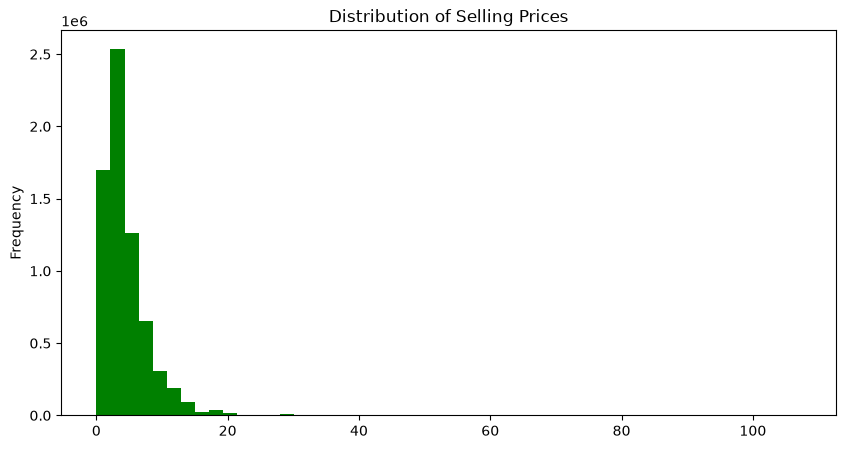

In [35]:
prices_df['sell_price'].plot(kind='hist',bins=50, figsize=(10,5), color='green')
plt.title('Distribution of Selling Prices')
plt.show() 

In [36]:
prices_df['sell_price'].describe()

count   6841121.000000
mean          4.410952
std           3.408814
min           0.010000
25%           2.180000
50%           3.470000
75%           5.840000
max         107.320000
Name: sell_price, dtype: float64

In [37]:
prices_df['sell_price'].skew()

np.float64(2.224996751921383)

In [38]:
store_prices = prices_df.groupby('store_id')['sell_price'].mean().sort_values(ascending=False)

In [39]:
store_prices.head(10)

store_id
WI_1   4.457712
CA_2   4.445500
WI_2   4.441717
CA_4   4.421580
WI_3   4.418117
CA_1   4.414233
CA_3   4.388229
TX_3   4.387365
TX_1   4.374569
TX_2   4.366766
Name: sell_price, dtype: float64

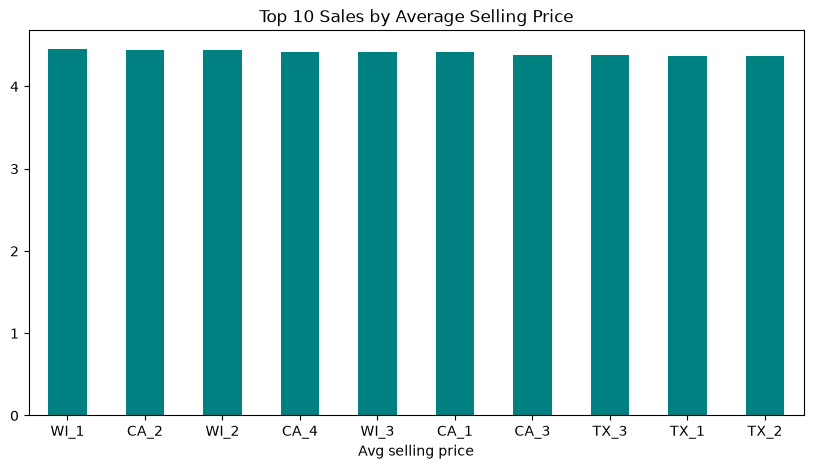

In [40]:
store_prices.head(10).plot(kind='bar',figsize=(10,5), color='teal' )
plt.title('Top 10 Sales by Average Selling Price')
plt.xlabel('store')
plt.xlabel('Avg selling price')
plt.xticks(rotation=0)
plt.show()

In [41]:
store_prices.tail()

store_id
CA_1   4.414233
CA_3   4.388229
TX_3   4.387365
TX_1   4.374569
TX_2   4.366766
Name: sell_price, dtype: float64

In [42]:
print('Highest avg point:', store_prices.max())
print('lowest avg point:', store_prices.min())

Highest avg point: 4.45771170965533
lowest avg point: 4.366766279623625


In [43]:
prices_df.columns

Index(['store_id', 'item_id', 'wm_yr_wk', 'sell_price'], dtype='str')

In [44]:
daily_cols = [col for col in sales_df.columns if col.startswith("d_")]

In [45]:
sales_long = sales_df.melt(
    id_vars=["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"],
    value_vars=daily_cols,
    var_name="d",
    value_name="sales"
)

In [46]:
sales_long.shape

(58327370, 8)

In [47]:
sales_df.shape

(30490, 1919)

In [48]:
sales_long.columns

Index(['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd',
       'sales'],
      dtype='str')

In [49]:
sales_long.head()


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [50]:
sales_with_calendar = sales_long.merge(calendar_df,on='d',how='left')

In [51]:
sales_with_calendar.shape

(58327370, 21)

In [52]:
calendar_df.shape

(1969, 14)

In [53]:
sales_long.shape

(58327370, 8)

In [54]:
sales_with_calendar_and_price = sales_with_calendar.merge(
    prices_df,
    on=['item_id','store_id','wm_yr_wk'],
    how='left'
)

In [55]:
sales_with_calendar_and_price[['item_id','store_id','date','sales','sell_price']].head()

,item_id,store_id,date,sales,sell_price
0,HOBBIES_1_001,CA_1,2011-01-29,0,NaN
1,HOBBIES_1_002,CA_1,2011-01-29,0,NaN
2,HOBBIES_1_003,CA_1,2011-01-29,0,NaN
3,HOBBIES_1_004,CA_1,2011-01-29,0,NaN
4,HOBBIES_1_005,CA_1,2011-01-29,0,NaN


In [56]:
sales_with_calendar_and_price['sell_price'].isna().sum()


np.int64(12299413)

In [57]:
sales_with_calendar_and_price.loc[
    sales_with_calendar_and_price["sell_price"].isna(),
    ["item_id", "store_id", "d", "wm_yr_wk", "sales"]
].head(10)

,item_id,store_id,d,wm_yr_wk,sales
0,HOBBIES_1_001,CA_1,d_1,11101,0
1,HOBBIES_1_002,CA_1,d_1,11101,0
2,HOBBIES_1_003,CA_1,d_1,11101,0
3,HOBBIES_1_004,CA_1,d_1,11101,0
4,HOBBIES_1_005,CA_1,d_1,11101,0
5,HOBBIES_1_006,CA_1,d_1,11101,0
6,HOBBIES_1_007,CA_1,d_1,11101,0
10,HOBBIES_1_011,CA_1,d_1,11101,0
12,HOBBIES_1_013,CA_1,d_1,11101,0
13,HOBBIES_1_014,CA_1,d_1,11101,0


In [58]:
missing_prices = sales_with_calendar_and_price[
    sales_with_calendar_and_price["sell_price"].isna()
]

In [59]:
missing_prices[['item_id','store_id','date', 'wm_yr_wk', 'sales']].head()

,item_id,store_id,date,wm_yr_wk,sales
0,HOBBIES_1_001,CA_1,2011-01-29,11101,0
1,HOBBIES_1_002,CA_1,2011-01-29,11101,0
2,HOBBIES_1_003,CA_1,2011-01-29,11101,0
3,HOBBIES_1_004,CA_1,2011-01-29,11101,0
4,HOBBIES_1_005,CA_1,2011-01-29,11101,0


In [60]:
sales_with_calendar_and_price['sales'].value_counts().head()

sales
0    39777094
1     7753194
2     3894493
3     2098127
4     1279524
Name: count, dtype: int64

In [61]:
prices_df[
    (prices_df['item_id'] == 'HOBBIES_1_001') &
    (prices_df['store_id'] == 'CA_1')
    ]['wm_yr_wk'].agg(['min','max'])


min    11325
max    11621
Name: wm_yr_wk, dtype: int64

In [62]:
sales_with_calendar_and_price.loc[
    sales_with_calendar_and_price["sell_price"].isna(),
    "wm_yr_wk"
].value_counts().head(10)

wm_yr_wk
11101    136906
11102    129605
11103    125797
11104    123837
11105    122199
11106    120092
11107    118223
11108    116802
11109    115759
11110    114415
Name: count, dtype: int64

In [63]:
missisng_count = sales_with_calendar_and_price['sell_price'].isna().sum()
total_count = len(sales_with_calendar_and_price)

In [64]:
print('Missing_prices:', missing_prices)
print('Percent missing:', round(missisng_count/total_count * 100, 2),"%")

Missing_prices:                                        id          item_id      dept_id  \
0           HOBBIES_1_001_CA_1_validation    HOBBIES_1_001    HOBBIES_1   
1           HOBBIES_1_002_CA_1_validation    HOBBIES_1_002    HOBBIES_1   
2           HOBBIES_1_003_CA_1_validation    HOBBIES_1_003    HOBBIES_1   
3           HOBBIES_1_004_CA_1_validation    HOBBIES_1_004    HOBBIES_1   
4           HOBBIES_1_005_CA_1_validation    HOBBIES_1_005    HOBBIES_1   
...                                   ...              ...          ...   
56108534  HOUSEHOLD_1_278_CA_3_validation  HOUSEHOLD_1_278  HOUSEHOLD_1   
56110517      FOODS_3_595_CA_3_validation      FOODS_3_595      FOODS_3   
56111702  HOUSEHOLD_1_400_CA_4_validation  HOUSEHOLD_1_400  HOUSEHOLD_1   
56123886  HOUSEHOLD_1_386_WI_1_validation  HOUSEHOLD_1_386  HOUSEHOLD_1   
56126576  HOUSEHOLD_1_020_WI_2_validation  HOUSEHOLD_1_020  HOUSEHOLD_1   

             cat_id store_id state_id       d  sales        date  wm_yr_wk  \
0    

In [65]:
sales_with_calendar_and_price["sell_price"].isna().sum()


np.int64(12299413)

In [66]:
sales_with_calendar_and_price.shape

(58327370, 22)

In [68]:
daily_totals = sales_with_calendar_and_price.groupby("date")["sales"].sum()
daily_totals.head()


date
2011-01-29    32631
2011-01-30    31749
2011-01-31    23783
2011-02-01    25412
2011-02-02    19146
Name: sales, dtype: int64

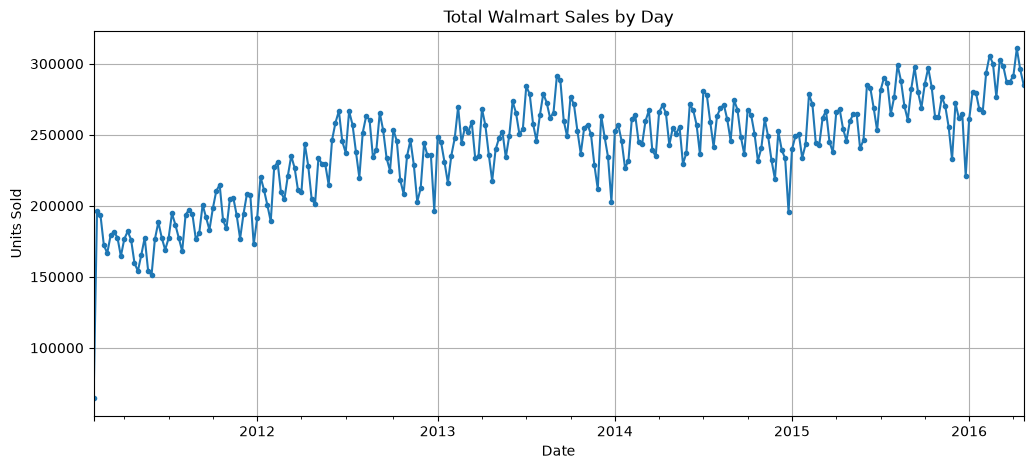

In [85]:
daily_totals.index = pd.to_datetime(daily_totals.index)


weekly_totals = daily_totals.resample("W").sum()
weekly_totals.plot(figsize=(12, 5), kind='line', marker='.')
plt.title("Total Walmart Sales by Day")
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.grid()
plt.show()

This chart shows weekly total sales from 2011 to 2016. Sales generally rose over this period, with the lowest point occuring around 2011/2012 and the highest peak appearing toward 2016

In [81]:
weekly_totals.describe()

count      274.000000
mean    239764.266423
std      36135.662421
min      64380.000000
25%     218371.000000
50%     245799.000000
75%     265274.000000
max     310767.000000
Name: sales, dtype: float64

In [86]:
print('Lowest week:', weekly_totals.idxmin(), weekly_totals.min())
print('Highest week:', weekly_totals.idxmax(), weekly_totals.max())

Lowest week: 2011-01-30 00:00:00 64380
Highest week: 2016-04-10 00:00:00 310767


In [88]:
weekly_sales_by_year = weekly_totals.resample('YE').mean()
weekly_sales_by_year

date
2011-12-31   180982.645833
2012-12-31   230117.339623
2013-12-31   251993.942308
2014-12-31   251231.211538
2015-12-31   264512.019231
2016-12-31   287628.823529
Freq: YE-DEC, Name: sales, dtype: float64

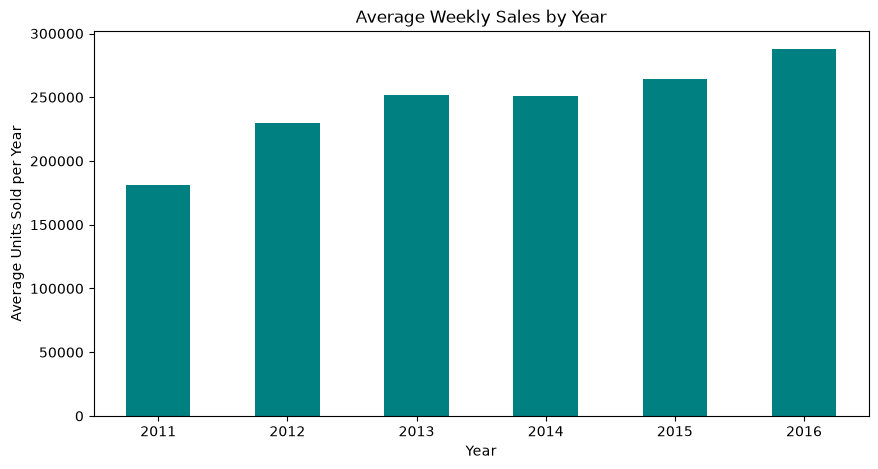

In [91]:
weekly_sales_by_year.plot(kind='bar', figsize=(10,5), color= 'teal')
plt.title('Average Weekly Sales by Year')
plt.xlabel('Year')
plt.ylabel('Average Units Sold per Year')
plt.xticks(rotation=0)
plt.show()

Total weekly sales generally increased from 2011 to 2016. Average weekly sales rose from about 181,000 units in 2011 to about 288,000 in 2016, with a slight dip in 2014. Weekly sales were lowest on January 30, 2011 (64,380 units) and highest on April 10, 2016 (310,767 units). The 2011 and 2016 averages cover partial years.


Summary: Daily sales were reshaped into product, store, and day records, then matched with calendar and price data. Some rows had no matching price, so those prices remain unknown. Weekly sales generally rose from 2011 to 2016, with a small dip in 2014. The lowest week was January 30, 2011 (64,380 units), and the highest was April 10, 2016 (310,767 units). The 2011 and 2016 yearly averages cover partial years.